# DINOv2 Guide-Semantic Patch Matching

Guide images define a weak semantic direction (likely bumper vs likely non-bumper), then test patches are scored by cosine similarity to that guide-only direction.


In [12]:
import glob
import math
import os
import sys

import numpy as np
import torch
import torch.nn.functional as F
import PIL.Image
import matplotlib.pyplot as plt
from transformers import AutoImageProcessor, Dinov2Model

%matplotlib inline


## Configuration

Adjust these to match your setup:
- **GUIDE_FOLDER**: folder of images sharing the feature you want to detect
- **TEST_IMAGE**: the image you want to search for that feature in
- **IMG_SIZE**: DINOv2-base works natively at 518 (14×37 patches). Use 1024 for finer grids but slower inference.


In [13]:
# ── Edit these ────────────────────────────────────────────────────────
GUIDE_FOLDER = "./datasets/robots/train/"          # folder of guide images
TEST_IMAGE   = "./datasets/robots/test-stream.png" # image to analyse
IMG_SIZE     = 518                                 # 518 = DINOv2-base native, 1024 = finer grid
# ──────────────────────────────────────────────────────────────────────

DINO_MODEL_ID    = "facebook/dinov2-base"
PATCH_SIZE       = 14
N_PCA_COMPONENTS = 3   # 3 components -> RGB visualisation

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


## Helper functions

In [14]:
def load_images(paths: list, size: int = IMG_SIZE) -> list:
    """Load and resize images to a square."""
    imgs = []
    for p in paths:
        try:
            _LANCZOS = PIL.Image.Resampling.LANCZOS
        except AttributeError:
            _LANCZOS = PIL.Image.LANCZOS
        img = PIL.Image.open(p).convert("RGB").resize((size, size), resample=_LANCZOS)
        imgs.append(img)
    return imgs


def plot_images(images, labels=None, figsize=20):
    """Plot a row of images side by side."""
    fig, axes = plt.subplots(1, len(images), figsize=(figsize, figsize // len(images) + 2))
    if len(images) == 1:
        axes = [axes]
    for i, (ax, img) in enumerate(zip(axes, images)):
        ax.imshow(np.array(img))
        ax.axis("off")
        if labels:
            ax.set_title(labels[i])
    plt.tight_layout()
    plt.show()


def get_patch_features(
    images: list,
    processor: AutoImageProcessor,
    model: Dinov2Model,
    device: str,
    batch_size: int = 4,
) -> torch.Tensor:
    """
    Run DINOv2 forward pass → patch-level features (CLS token removed).
    Returns: (N, num_patches, hidden_dim)
    """
    all_patch_features = []
    for i in range(0, len(images), batch_size):
        batch_images = images[i:i + batch_size]
        inputs = processor(images=batch_images, return_tensors="pt").to(device)
        with torch.inference_mode():
            outputs = model(**inputs)
        # drop CLS token at index 0
        batch_features = outputs.last_hidden_state[:, 1:, :].cpu()
        all_patch_features.append(batch_features)
        del inputs, outputs, batch_features
        if str(device).startswith("cuda"):
            torch.cuda.empty_cache()

    return torch.cat(all_patch_features, dim=0)


def thresholded_pca(x: torch.Tensor, n_components: int = N_PCA_COMPONENTS) -> torch.Tensor:
    """
    Baseline reference utility (not used by the main semantic-direction workflow).
    PCA on patch features, then zero out patches whose primary component
    is negative (not aligned with the dominant direction).
    Returns normalised (N, n_components) tensor in [0, 1].
    """
    x = x - x.mean(dim=0)
    # torch.linalg.svd returns (U, S, Vh) — transpose Vh to get V
    U, S, Vh = torch.linalg.svd(x, full_matrices=False)
    V = Vh.T
    components = x @ V[:, :n_components]

    # anchor sign: flip if median PC1 projection is negative
    if components[:, 0].median() < 0:
        components = -components

    # threshold: keep only patches aligned with PC1
    mask = components[:, 0] > 0

    # normalise to [0, 1]
    comp_min = components.min(dim=0, keepdim=True).values
    comp_max = components.max(dim=0, keepdim=True).values
    components = (components - comp_min) / (comp_max - comp_min + 1e-8)

    # zero out non-matching patches
    components[~mask] = 0.0
    return components


def likely_bumper_pixel_mask(image: PIL.Image.Image) -> np.ndarray:
    """
    Weak color prior for likely bumper regions (red or blue in HSV).
    Returns a boolean pixel mask of shape (H, W).
    """
    hsv = np.array(image.convert("HSV"), dtype=np.float32)
    h = hsv[..., 0] * (360.0 / 255.0)
    s = hsv[..., 1] / 255.0
    v = hsv[..., 2] / 255.0

    red = (h <= 18.0) | (h >= 342.0)
    blue = (h >= 185.0) & (h <= 265.0)
    chromatic = s >= 0.25
    not_too_dark = v >= 0.15
    return (red | blue) & chromatic & not_too_dark


def pixel_mask_to_patch_mask(
    pixel_mask: np.ndarray,
    grid_h: int,
    grid_w: int,
    min_fraction: float = 0.05,
) -> torch.Tensor:
    """Project a pixel mask to a boolean patch mask of shape (grid_h*grid_w,)."""
    h, w = pixel_mask.shape
    if h % grid_h != 0 or w % grid_w != 0:
        raise ValueError(f"Mask shape {pixel_mask.shape} is not divisible by grid {grid_h}x{grid_w}")

    patch_h, patch_w = h // grid_h, w // grid_w
    patch_ratio = pixel_mask.astype(np.float32).reshape(grid_h, patch_h, grid_w, patch_w).mean(axis=(1, 3))
    return torch.from_numpy((patch_ratio >= min_fraction).reshape(-1))


def build_guide_patch_masks(
    guide_images: list,
    grid_h: int,
    grid_w: int,
    min_fraction: float = 0.05,
) -> torch.Tensor:
    """Build weak positive/negative labels per guide patch from RGB heuristics."""
    masks = []
    for img in guide_images:
        pix_mask = likely_bumper_pixel_mask(img)
        masks.append(pixel_mask_to_patch_mask(pix_mask, grid_h, grid_w, min_fraction=min_fraction))
    return torch.stack(masks, dim=0).bool()


def build_semantic_direction(
    guide_patches: torch.Tensor,
    guide_patch_masks: torch.Tensor,
) -> tuple[torch.Tensor, dict]:
    """
    Build a guide-only semantic direction:
      normalize(mean(likely_bumper_patches)) - normalize(mean(likely_non_bumper_patches)).
    """
    flat_patches = guide_patches.reshape(-1, guide_patches.shape[-1])
    flat_mask = guide_patch_masks.reshape(-1)

    positives = flat_patches[flat_mask]
    negatives = flat_patches[~flat_mask]

    if positives.shape[0] == 0 or negatives.shape[0] == 0:
        raise ValueError(
            "Guide heuristic produced an empty positive or negative set. "
            "Adjust color thresholds or min_fraction."
        )

    pos_mean = F.normalize(positives.mean(dim=0, keepdim=True), dim=-1)
    neg_mean = F.normalize(negatives.mean(dim=0, keepdim=True), dim=-1)
    direction = F.normalize(pos_mean - neg_mean, dim=-1).squeeze(0)

    stats = {
        "positive_patches": int(positives.shape[0]),
        "negative_patches": int(negatives.shape[0]),
        "total_patches": int(flat_patches.shape[0]),
    }
    return direction, stats


def cosine_patch_scores(patches: torch.Tensor, direction: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """Cosine similarity in [0, 1], returned as (num_patches, 1) for heatmap rendering."""
    direction = F.normalize(direction.unsqueeze(0), dim=-1).squeeze(0)
    scores = F.cosine_similarity(patches, direction.unsqueeze(0), dim=-1)

    min_v, max_v = scores.min(), scores.max()
    if (max_v - min_v).abs() < eps:
        return torch.zeros_like(scores).unsqueeze(-1)

    scores = (scores - min_v) / (max_v - min_v + eps)
    return scores.unsqueeze(-1)


def unflatten_to_grid(flat: torch.Tensor, grid_h: int, grid_w: int) -> np.ndarray:
    """Reshape (grid_h*grid_w, C) → (grid_h, grid_w, C) numpy array."""
    return flat.reshape(grid_h, grid_w, -1).cpu().numpy()


## Load guide images

Found 15 guide image(s)
  ./datasets/robots/train/Robot1.png
  ./datasets/robots/train/Robot10.png
  ./datasets/robots/train/Robot11.png
  ./datasets/robots/train/Robot12.png
  ./datasets/robots/train/Robot13.png
  ./datasets/robots/train/Robot14.png
  ./datasets/robots/train/Robot15.png
  ./datasets/robots/train/Robot2.png
  ./datasets/robots/train/Robot3.png
  ./datasets/robots/train/Robot4.png
  ./datasets/robots/train/Robot5.png
  ./datasets/robots/train/Robot6.png
  ./datasets/robots/train/Robot7.png
  ./datasets/robots/train/Robot8.png
  ./datasets/robots/train/Robot9.png


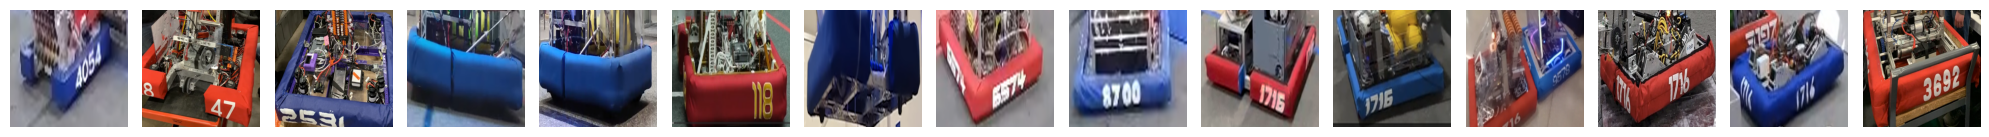

In [15]:
exts = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp")
guide_paths = []
for ext in exts:
    guide_paths.extend(glob.glob(os.path.join(GUIDE_FOLDER, ext)))
guide_paths = sorted(set(guide_paths))

print(f"Found {len(guide_paths)} guide image(s)")
for p in guide_paths:
    print(f"  {p}")

if not guide_paths:
    print(f"No guide images found in {GUIDE_FOLDER}. Add at least one image and rerun.")
    raise SystemExit(1)

guide_imgs = load_images(guide_paths, size=IMG_SIZE)
plot_images(guide_imgs)

## Load test image

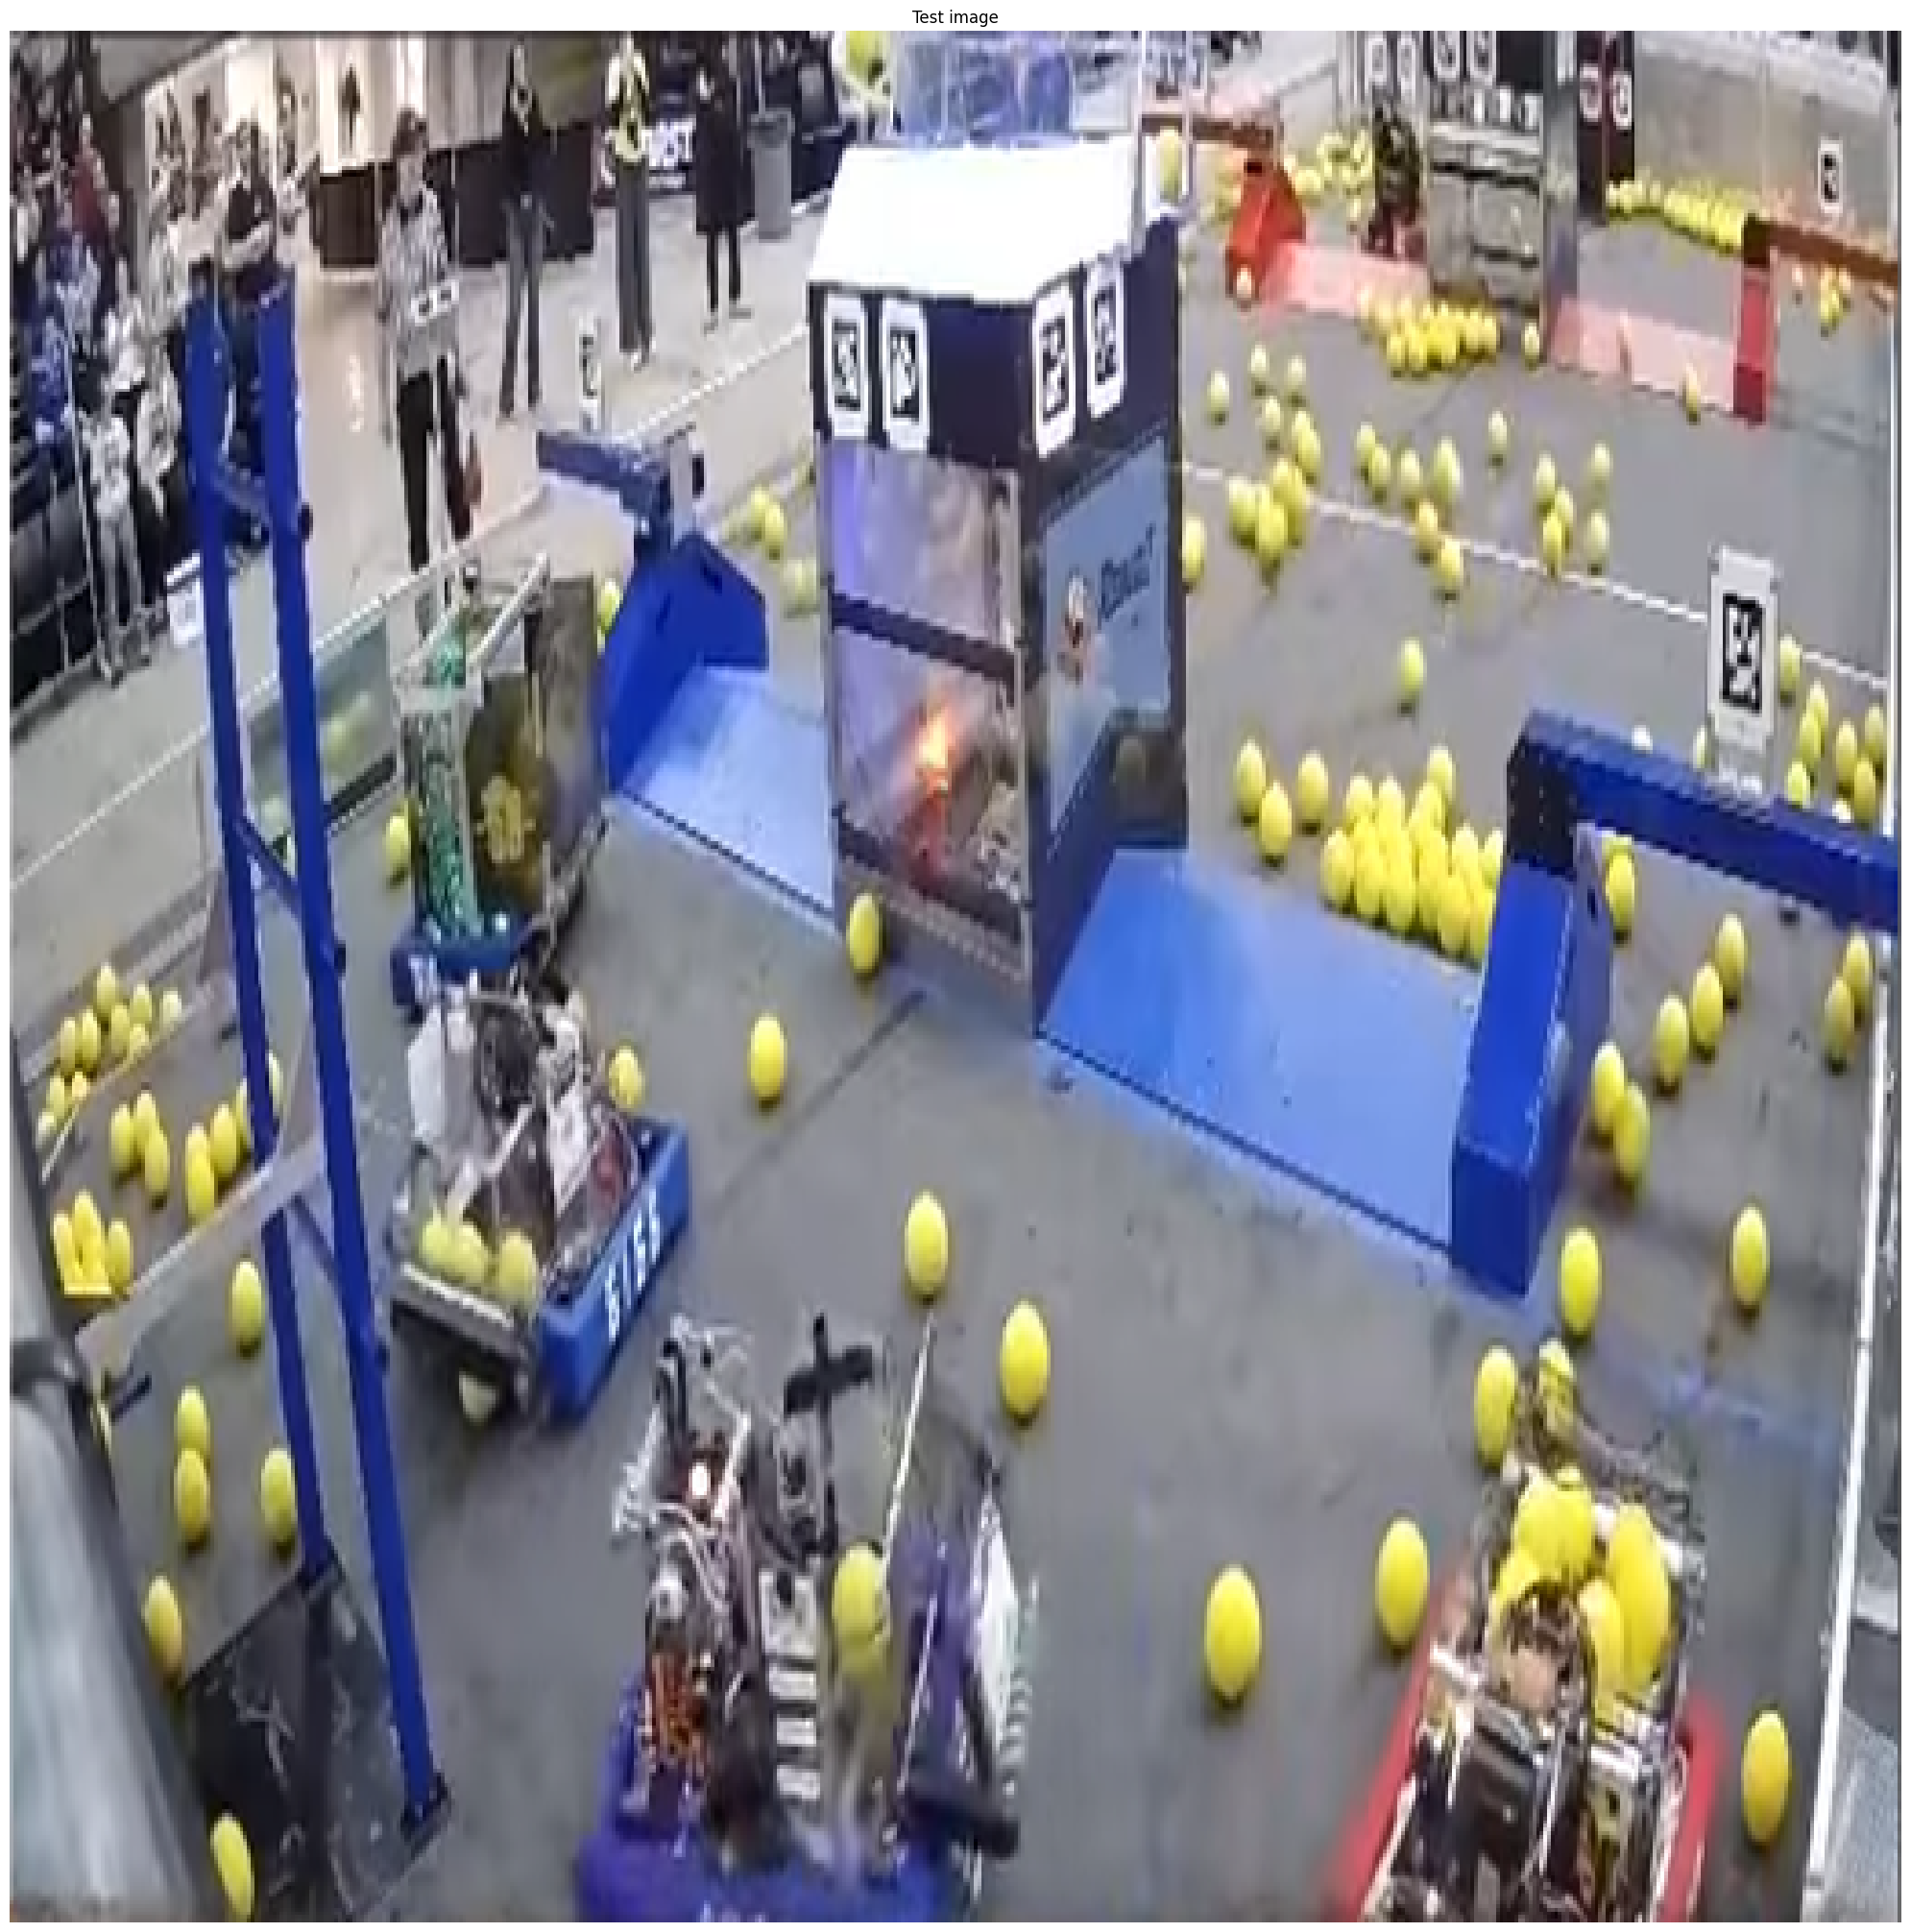

In [16]:
test_img = load_images([TEST_IMAGE], size=IMG_SIZE)[0]
plot_images([test_img], labels=["Test image"])

## Load DINOv2 model

First run will download the weights from HuggingFace (~350 MB for dinov2-base).


In [17]:
processor = AutoImageProcessor.from_pretrained(
    DINO_MODEL_ID, do_center_crop=False, do_resize=False,
)
model = Dinov2Model.from_pretrained(DINO_MODEL_ID).to(device)
model.eval()
print("Model loaded!")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Model loaded!


## Extract features

We encode the test image and all guides in a single forward pass so they share identical normalisation.


In [18]:
all_imgs = [test_img] + guide_imgs
print(f"Encoding {len(all_imgs)} images ...")

all_features = get_patch_features(all_imgs, processor, model, device)
print(f"Patch features shape: {all_features.shape}")
# (1 + N_guides, num_patches, hidden_dim)

test_patches  = all_features[0].cpu()       # (num_patches, D)
guide_patches = all_features[1:].cpu()      # (N_guides, num_patches, D)

# flatten guides → (N_guides * num_patches, D)
flat_guides = guide_patches.reshape(-1, guide_patches.shape[-1])
print(f"Test patches:  {test_patches.shape}")
print(f"Guide patches: {flat_guides.shape}")

n_patches = test_patches.shape[0]
grid_h = grid_w = int(math.sqrt(n_patches))
assert grid_h * grid_w == n_patches, f"Patch count {n_patches} is not a perfect square"

guide_patch_masks = build_guide_patch_masks(guide_imgs, grid_h, grid_w, min_fraction=0.05)
print(
    f"Heuristic guide positives: {int(guide_patch_masks.sum().item())} / {guide_patch_masks.numel()} patches"
)
print(f"Heatmap grid: {grid_h}x{grid_w}")


Encoding 16 images ...
Patch features shape: torch.Size([16, 1369, 768])
Test patches:  torch.Size([1369, 768])
Guide patches: torch.Size([20535, 768])
Heuristic guide positives: 10686 / 20535 patches
Heatmap grid: 37x37


## Build guide semantic direction (guide-only)


In [19]:
semantic_direction, direction_stats = build_semantic_direction(guide_patches, guide_patch_masks)

print("Guide-only semantic direction stats:")
for k, v in direction_stats.items():
    print(f"  {k}: {v}")


Guide-only semantic direction stats:
  positive_patches: 10686
  negative_patches: 9849
  total_patches: 20535


## Score test patches with guide-derived semantic direction


In [20]:
# score test patches against the guide-only semantic direction
# (no concatenation with test patches in basis construction)
test_scores = cosine_patch_scores(test_patches, semantic_direction)
heatmap_semantic = unflatten_to_grid(test_scores, grid_h, grid_w).squeeze(-1)

# visualise how often each patch position was tagged as likely bumper in guides
guide_prior = guide_patch_masks.float().mean(dim=0)
heatmap_guide_prior = guide_prior.reshape(grid_h, grid_w).cpu().numpy()

print("Computed semantic heatmap from guide-only contrastive direction")


Computed semantic heatmap from guide-only contrastive direction


## Visualise heuristic prior and semantic heatmap


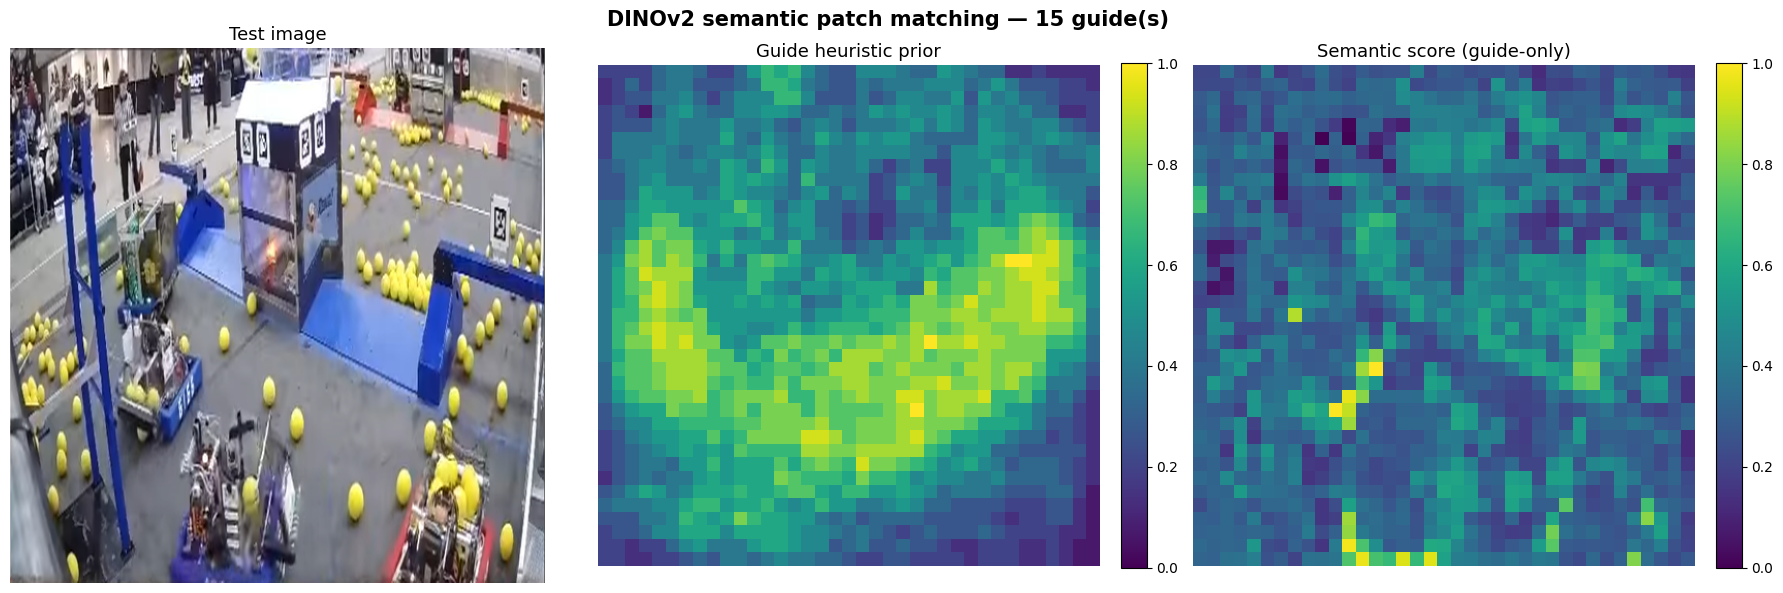

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(np.array(test_img))
axes[0].set_title("Test image", fontsize=13)
axes[0].axis("off")

im1 = axes[1].imshow(heatmap_guide_prior, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Guide heuristic prior", fontsize=13)
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(heatmap_semantic, cmap="viridis", vmin=0, vmax=1)
axes[2].set_title("Semantic score (guide-only)", fontsize=13)
axes[2].axis("off")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

fig.suptitle(
    f"DINOv2 semantic patch matching — {len(guide_paths)} guide(s)",
    fontsize=15, fontweight="bold",
)
plt.tight_layout()
plt.show()


## Overlay semantic heatmap on original image


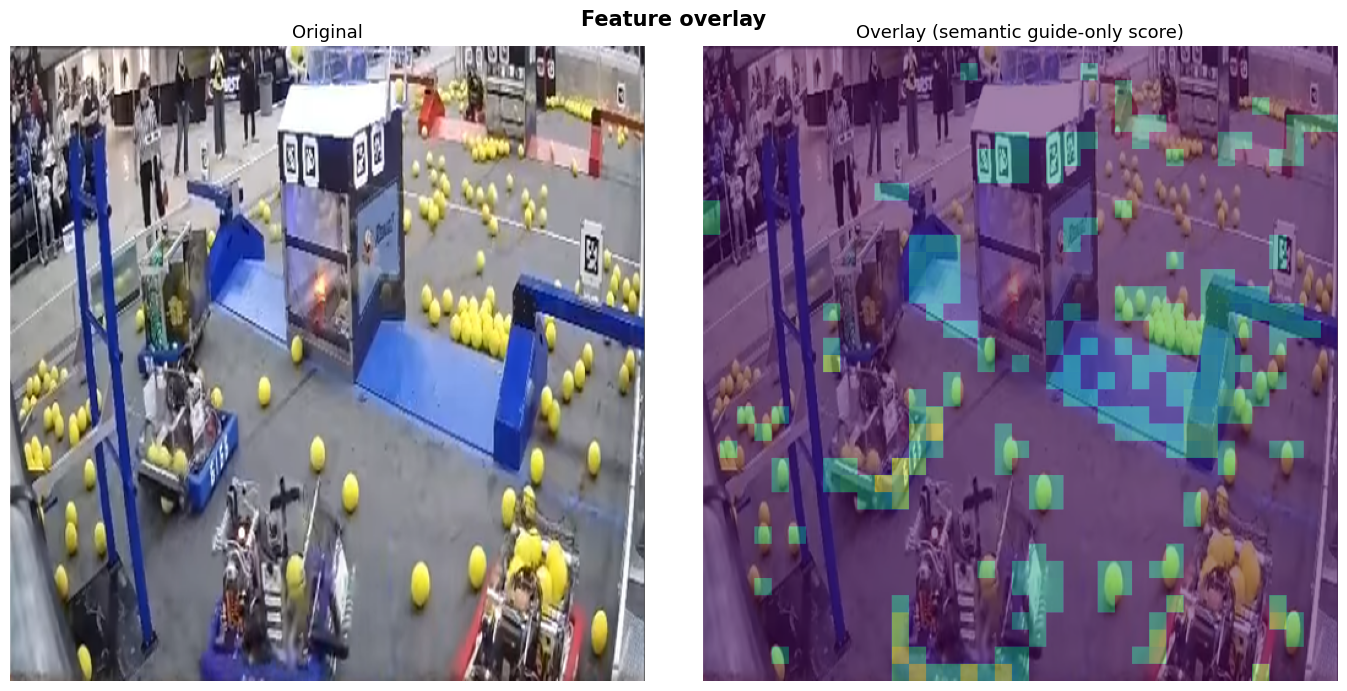

In [22]:
from PIL import Image as PILImage

# upscale heatmap to image size
heatmap_img = PILImage.fromarray((heatmap_semantic * (heatmap_semantic > 0.5) * 255).astype(np.uint8))
# Pillow 10+ moved NEAREST to Image.Resampling.NEAREST
try:
    _NEAREST = PILImage.Resampling.NEAREST
except AttributeError:
    _NEAREST = PILImage.NEAREST
heatmap_img = heatmap_img.resize((IMG_SIZE, IMG_SIZE), resample=_NEAREST)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(np.array(test_img))
axes[0].set_title("Original", fontsize=13)
axes[0].axis("off")

axes[1].imshow(np.array(test_img))
axes[1].imshow(np.array(heatmap_img), alpha=0.5, cmap="viridis")
axes[1].set_title("Overlay (semantic guide-only score)", fontsize=13)
axes[1].axis("off")

plt.suptitle("Feature overlay", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()
